<a href="https://colab.research.google.com/github/Hithavan31/BIS_PROGRAMS/blob/main/1BM24CS118_Manufacturing_Job_Shop_Scheduling_Ant_Colony_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter number of jobs: 2
Enter number of machines: 2

Enter number of operations for Job 1: 2
  Enter machine number (1-2) for operation 1: 1
  Enter processing time for operation 1: 3
  Enter machine number (1-2) for operation 2: 2
  Enter processing time for operation 2: 2

Enter number of operations for Job 2: 2
  Enter machine number (1-2) for operation 1: 2
  Enter processing time for operation 1: 4
  Enter machine number (1-2) for operation 2: 1
  Enter processing time for operation 2: 2

Enter number of ants: 10
Enter maximum iterations: 100
Enter alpha (pheromone importance): 1
Enter beta (heuristic importance): 2
Enter evaporation rate (0 to 1): 0.5
Iteration 1: Best Makespan = 6
Iteration 2: Best Makespan = 6
Iteration 3: Best Makespan = 6
Iteration 4: Best Makespan = 6
Iteration 5: Best Makespan = 6
Iteration 6: Best Makespan = 6
Iteration 7: Best Makespan = 6
Iteration 8: Best Makespan = 6
Iteration 9: Best Makespan = 6
Iteration 10: Best Makespan = 6
Iteration 11: Best Make

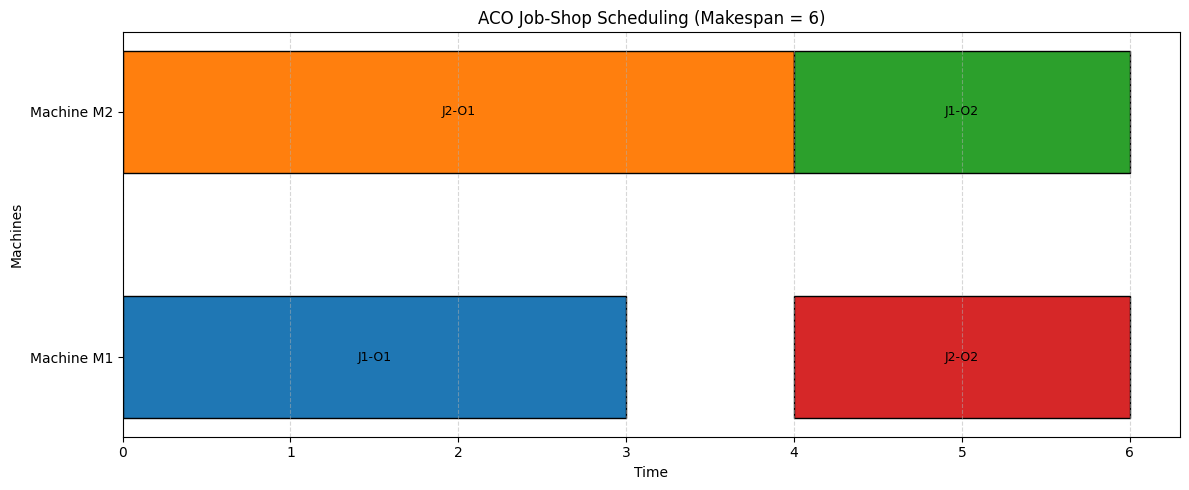

In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------
# 1. USER INPUT
# -----------------------------------

num_jobs = int(input("Enter number of jobs: "))
num_machines = int(input("Enter number of machines: "))

jobs = []

for j in range(num_jobs):
    operations = []
    n = int(input(f"\nEnter number of operations for Job {j+1}: "))

    for k in range(n):
        machine = int(input(
            f"  Enter machine number (1-{num_machines}) for operation {k+1}: "
        )) - 1

        processing_time = int(input(
            f"  Enter processing time for operation {k+1}: "
        ))

        if not (0 <= machine < num_machines) or processing_time <= 0:
            raise ValueError("Invalid machine number or processing time")

        operations.append((machine, processing_time))

    jobs.append(operations)


# -----------------------------------
# 2. ACO PARAMETERS
# -----------------------------------

num_ants = int(input("\nEnter number of ants: "))
iterations = int(input("Enter maximum iterations: "))

alpha = float(input("Enter alpha (pheromone importance): "))
beta = float(input("Enter beta (heuristic importance): "))
rho = float(input("Enter evaporation rate (0 to 1): "))

if num_ants <= 0 or iterations <= 0:
    raise ValueError("Ants and iterations must be positive")

if alpha < 0 or beta < 0 or not 0 < rho < 1:
    raise ValueError("Invalid ACO parameters")


# -----------------------------------
# 3. OPERATION IDENTIFICATION
# -----------------------------------

operation_ids = []
total_operations = 0

for job in jobs:
    ids = []

    for _ in job:
        ids.append(total_operations)
        total_operations += 1

    operation_ids.append(ids)

# Last index represents the starting node
START = total_operations

# Initialize pheromone matrix
pheromone = np.ones((total_operations + 1, total_operations))


# -----------------------------------
# 4. FIND EARLIEST AVAILABLE TIME
# -----------------------------------

def find_earliest_start(machine_schedule, ready_time, duration):

    start = ready_time

    for s, e, job, op in machine_schedule:

        if start + duration <= s:
            break

        if start < e:
            start = e

    return start


# -----------------------------------
# 5. CONSTRUCT A SCHEDULE USING AN ANT
# -----------------------------------

def construct_solution():

    job_next = [0] * num_jobs
    job_ready = [0] * num_jobs

    machine_schedule = [[] for _ in range(num_machines)]

    schedule = []
    sequence = []

    last_operation = START

    while len(schedule) < total_operations:

        candidates = []

        # Find next available operation of each job
        for j in range(num_jobs):

            if job_next[j] < len(jobs[j]):

                op_index = job_next[j]

                machine, duration = jobs[j][op_index]

                start = find_earliest_start(
                    machine_schedule[machine],
                    job_ready[j],
                    duration
                )

                end = start + duration

                op_id = operation_ids[j][op_index]

                # Heuristic: prefer operations with
                # earlier estimated completion times
                heuristic = 1.0 / (end + 1)

                candidates.append(
                    (j, op_index, machine, duration,
                     start, end, op_id, heuristic)
                )

        # Calculate selection probabilities
        weights = []

        for c in candidates:

            op_id = c[6]
            heuristic = c[7]

            weight = (
                pheromone[last_operation, op_id] ** alpha
            ) * (
                heuristic ** beta
            )

            weights.append(weight)

        probabilities = np.array(weights, dtype=float)
        probabilities /= probabilities.sum()

        # Select an operation probabilistically
        selected = random.choices(
            candidates,
            weights=probabilities,
            k=1
        )[0]

        j, op_index, machine, duration, start, end, op_id, _ = selected

        # Add operation to machine schedule
        machine_schedule[machine].append(
            (start, end, j, op_index)
        )

        machine_schedule[machine].sort(key=lambda x: x[0])

        # Update job completion time
        job_ready[j] = end
        job_next[j] += 1

        schedule.append({
            "job": j + 1,
            "operation": op_index + 1,
            "machine": machine + 1,
            "start": start,
            "end": end,
            "duration": duration
        })

        sequence.append(op_id)

        last_operation = op_id

    makespan = max(job_ready)

    return schedule, sequence, makespan


# -----------------------------------
# 6. ACO OPTIMIZATION
# -----------------------------------

best_schedule = None
best_sequence = None
best_makespan = float("inf")

Q = 100

for iteration in range(iterations):

    iteration_best = None
    iteration_best_sequence = None
    iteration_best_makespan = float("inf")

    # Each ant constructs one schedule
    for ant in range(num_ants):

        schedule, sequence, makespan = construct_solution()

        if makespan < iteration_best_makespan:

            iteration_best_makespan = makespan
            iteration_best = schedule
            iteration_best_sequence = sequence

        if makespan < best_makespan:

            best_makespan = makespan
            best_schedule = schedule
            best_sequence = sequence

    # Evaporate pheromones
    pheromone *= (1 - rho)

    # Deposit pheromone for iteration's best solution
    deposit = Q / iteration_best_makespan

    previous = START

    for op_id in iteration_best_sequence:

        pheromone[previous, op_id] += deposit
        previous = op_id

    # Extra reinforcement for global best solution
    if best_sequence is not None:

        deposit = Q / best_makespan
        previous = START

        for op_id in best_sequence:

            pheromone[previous, op_id] += deposit
            previous = op_id

    print(
        f"Iteration {iteration + 1}: "
        f"Best Makespan = {best_makespan}"
    )


# -----------------------------------
# 7. DISPLAY BEST SCHEDULE
# -----------------------------------

print("\n========== OPTIMIZED JOB SCHEDULE ==========")

for m in range(num_machines):

    print(f"\nMachine M{m+1}:")

    machine_operations = [
        op for op in best_schedule
        if op["machine"] == m + 1
    ]

    machine_operations.sort(key=lambda x: x["start"])

    for op in machine_operations:

        print(
            f"J{op['job']}-O{op['operation']} : "
            f"{op['start']} - {op['end']}"
        )

print("\nMinimum Makespan:", best_makespan)


# -----------------------------------
# 8. GANTT CHART
# -----------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

for op in best_schedule:

    machine = op["machine"] - 1

    ax.barh(
        machine,
        op["duration"],
        left=op["start"],
        height=0.5,
        edgecolor="black"
    )

    ax.text(
        op["start"] + op["duration"] / 2,
        machine,
        f"J{op['job']}-O{op['operation']}",
        ha="center",
        va="center",
        fontsize=9
    )

ax.set_yticks(range(num_machines))
ax.set_yticklabels(
    [f"Machine M{i+1}" for i in range(num_machines)]
)

ax.set_xlabel("Time")
ax.set_ylabel("Machines")
ax.set_title(f"ACO Job-Shop Scheduling (Makespan = {best_makespan})")

ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()